In [1]:
# ------------------------------------------------------------
# Draw 5,000 values of every parameter from its distribution
# (the "dist", "a", "b" columns we filled in during Step 2)
# ------------------------------------------------------------
import time
import numpy as np
import pandas as pd
from markov_model import load_inputs, run_both

p, S = load_inputs()
inputs = pd.read_csv("../outputs/inputs.csv", index_col="name")
WTP = S["wtp"]

def sample_inputs(inputs, n, seed=2026):
    """
    Return {parameter name: array of n random draws}.
    Fixing the seed makes the 5,000 draws identical on every run, so the
    results are reproducible (a CDA-AMC requirement).
    """
    rng = np.random.default_rng(seed)
    draws = {}
    for name, row in inputs.iterrows():
        base = row["base"]

        if row["dist"] == "beta":
            # Probabilities and utilities: bounded between 0 and 1.
            # alpha + beta = effective sample size; mean = base.
            n_eff = row["a"]
            draws[name] = rng.beta(base * n_eff, (1 - base) * n_eff, size=n)

        elif row["dist"] == "lognormal":
            # Odds ratios and relative risks: always positive, skewed.
            # Work on the log scale: SD = (ln(upper CI) - ln(lower CI)) / (2 x 1.96)
            sd = (np.log(row["b"]) - np.log(row["a"])) / (2 * 1.96)
            draws[name] = np.exp(rng.normal(np.log(base), sd, size=n))

        elif row["dist"] == "gamma":
            # Costs: positive, right-skewed. CV = SD / mean = 25%.
            cv = row["a"]
            shape = 1 / cv**2
            draws[name] = rng.gamma(shape, base / shape, size=n)

        elif row["dist"] == "normal":
            # Utility decrements: mean and standard error
            draws[name] = rng.normal(base, row["a"], size=n)

        else:
            # "fixed": drug prices. CADTH doesn't vary list prices in the PSA
            # (they're known); price uncertainty is tested in Steps 5 and 7.
            draws[name] = np.full(n, base)
    return draws

N = 5000
draws = sample_inputs(inputs, N)

# Sanity check: the draws should centre on the base values
check = pd.DataFrame({
    "base":      inputs["base"],
    "draw mean": {k: v.mean() for k, v in draws.items()},
    "2.5%":      {k: np.percentile(v, 2.5) for k, v in draws.items()},
    "97.5%":     {k: np.percentile(v, 97.5) for k, v in draws.items()},
})
print(check.loc[["p_stroke", "or_apx_stroke", "or_apx_ich", "u_af", "c_stroke_major"]].round(4))

                      base   draw mean        2.5%        97.5%
p_stroke            0.0160      0.0160      0.0138       0.0183
or_apx_stroke       0.7900      0.7936      0.6509       0.9574
or_apx_ich          0.4200      0.4270      0.3034       0.5858
u_af                0.8100      0.8097      0.6767       0.9116
c_stroke_major  77873.8015  77914.9039  44453.3938  119948.0159


In [2]:
# ------------------------------------------------------------
# The model was written so every parameter can be an ARRAY.
# Passing arrays runs all 5,000 simulations at once: no loop needed.
# ------------------------------------------------------------
t0 = time.time()
apx, war = run_both(draws, S)
print(f"5,000 simulations x 2 arms in {time.time() - t0:.1f} seconds")

psa = pd.DataFrame({"cost_apx": apx["cost"], "cost_war": war["cost"],
                    "qaly_apx": apx["qaly"], "qaly_war": war["qaly"]})
psa["d_cost"] = psa["cost_apx"] - psa["cost_war"]
psa["d_qaly"] = psa["qaly_apx"] - psa["qaly_war"]
psa.to_csv("../outputs/psa_draws.csv", index=False)

def ci(x):
    return f"{x.mean():,.3f}  (95% CI {np.percentile(x, 2.5):,.3f} to {np.percentile(x, 97.5):,.3f})"

print("Incremental cost :", ci(psa["d_cost"]))
print("Incremental QALYs:", ci(psa["d_qaly"]))

# Which quadrant of the cost-effectiveness plane does each simulation land in?
quad = pd.Series({
    "Cheaper AND more QALYs (dominant)":  ((psa.d_cost < 0) & (psa.d_qaly > 0)).mean(),
    "Dearer, more QALYs (trade-off)":     ((psa.d_cost >= 0) & (psa.d_qaly > 0)).mean(),
    "Cheaper, fewer QALYs (trade-off)":   ((psa.d_cost < 0) & (psa.d_qaly <= 0)).mean(),
    "Dearer AND fewer QALYs (dominated)": ((psa.d_cost >= 0) & (psa.d_qaly <= 0)).mean(),
})
print(quad.map("{:.1%}".format).to_string())
print(f"P(apixaban cost-effective at $50,000/QALY): {(psa.d_qaly*WTP - psa.d_cost > 0).mean():.1%}")
print(f"Deterministic d_cost -5,608 vs PSA mean {psa.d_cost.mean():,.0f}")

5,000 simulations x 2 arms in 1.2 seconds
Incremental cost : -5,589.277  (95% CI -8,352.147 to -3,242.325)
Incremental QALYs: 0.236  (95% CI 0.127 to 0.359)
Cheaper AND more QALYs (dominant)     100.0%
Dearer, more QALYs (trade-off)          0.0%
Cheaper, fewer QALYs (trade-off)        0.0%
Dearer AND fewer QALYs (dominated)      0.0%
P(apixaban cost-effective at $50,000/QALY): 100.0%
Deterministic d_cost -5,608 vs PSA mean -5,589


In [3]:
# ------------------------------------------------------------
# Same 5,000 draws, only the apixaban price changed to Eliquis brand.
# Any difference between the two clouds is purely the price.
# ------------------------------------------------------------
brand_draws = dict(draws)
brand_draws["c_apixaban"] = np.full(N, 1.6336 * 2 * 365.25)
apx_b, war_b = run_both(brand_draws, S)
d_cost_b = apx_b["cost"] - war_b["cost"]
d_qaly_b = apx_b["qaly"] - war_b["qaly"]

print("Brand incremental cost:", ci(pd.Series(d_cost_b)))
print(f"Brand: share cost-saving {np.mean(d_cost_b < 0):.1%}")

# Cost-effectiveness acceptability curve (CEAC): at each willingness to pay,
# what share of simulations has positive net monetary benefit?
wtp_grid = np.arange(0, 100_001, 1_000)
ceac = pd.DataFrame({
    "wtp": wtp_grid,
    "generic": [np.mean(psa.d_qaly * w - psa.d_cost > 0) for w in wtp_grid],
    "brand":   [np.mean(d_qaly_b * w - d_cost_b > 0) for w in wtp_grid],
})
ceac.to_csv("../outputs/ceac.csv", index=False)
print(ceac[ceac.wtp.isin([0, 5000, 10000, 20000, 50000])].to_string(index=False))

Brand incremental cost: 1,292.064  (95% CI -1,345.172 to 3,499.109)
Brand: share cost-saving 13.8%
  wtp  generic  brand
    0      1.0 0.1380
 5000      1.0 0.4520
10000      1.0 0.7436
20000      1.0 0.9456
50000      1.0 0.9970


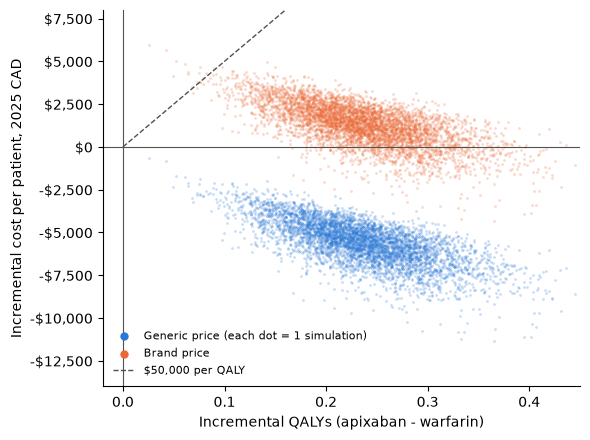

In [4]:
# ------------------------------------------------------------
# Each dot = one simulation. Below the horizontal line = cost-saving.
# Right of the vertical line = more QALYs. Below the dashed line = cost-effective.
# ------------------------------------------------------------
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(psa.d_qaly, psa.d_cost, s=4, alpha=0.25, color="#2a78d6", linewidths=0,
           label="Generic price (each dot = 1 simulation)")
ax.scatter(d_qaly_b, d_cost_b, s=4, alpha=0.25, color="#eb6834", linewidths=0,
           label="Brand price")
x = np.linspace(0, 0.45, 10)
ax.plot(x, x * WTP, color="#52514e", lw=1, ls="--", label="$50,000 per QALY")
ax.axhline(0, color="#52514e", lw=0.8)
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_xlim(-0.02, 0.45)
ax.set_ylim(-14000, 8000)
ax.set_xlabel("Incremental QALYs (apixaban - warfarin)")
ax.set_ylabel("Incremental cost per patient, 2025 CAD")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(
    lambda v, _: f"-${-v:,.0f}" if v < 0 else f"${v:,.0f}"))
ax.spines[["top", "right"]].set_visible(False)
leg = ax.legend(frameon=False, fontsize=8, loc="lower left", markerscale=3)
for h in leg.legend_handles:
    h.set_alpha(1)          # solid legend dots, even though the points are faded
plt.tight_layout()
plt.savefig("../outputs/fig_ce_plane.png", dpi=150)
plt.show()

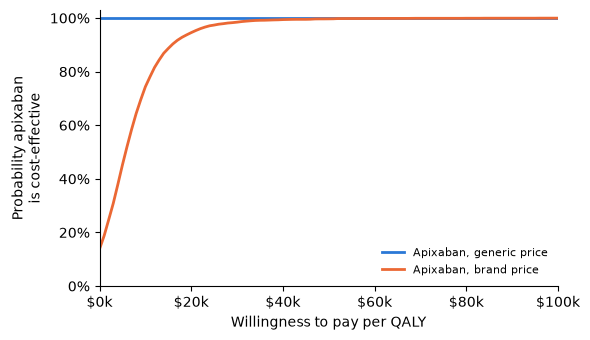

Running mean after 1,000 draws: -5,629; after 5,000: -5,589


In [5]:
# ------------------------------------------------------------
# CEAC chart
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(ceac.wtp, ceac.generic, color="#2a78d6", lw=2, label="Apixaban, generic price")
ax.plot(ceac.wtp, ceac.brand, color="#eb6834", lw=2, label="Apixaban, brand price")
ax.set_ylim(0, 1.03)
ax.set_xlim(0, 100_000)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:.0f}k"))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Willingness to pay per QALY")
ax.set_ylabel("Probability apixaban\nis cost-effective")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig("../outputs/fig_ceac.png", dpi=150)
plt.show()

# ------------------------------------------------------------
# Were 5,000 simulations enough? CADTH asks you to show the mean has
# settled down. If the running mean barely moves after 1,000 draws, yes.
# ------------------------------------------------------------
running = psa["d_cost"].expanding().mean()
print(f"Running mean after 1,000 draws: {running.iloc[999]:,.0f}; after 5,000: {running.iloc[-1]:,.0f}")